<a href="https://colab.research.google.com/github/Aynuroo/wine_quality_prediction/blob/main/Wine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# INSTALL PACKAGE

In [ ]:
pip install ucimlrepo

# IMPORT LIBRARIES

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from ucimlrepo import fetch_ucirepo

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# LOAD DATASET

In [ ]:
# Fetch dataset
wine = fetch_ucirepo(id=109)

# Features and target
X = wine.data.features
y = wine.data.targets

# Display first rows
print(X.head())

# Dataset shape
print("Dataset Shape:", X.shape)

   Alcohol  Malicacid   Ash  Alcalinity_of_ash  Magnesium  Total_phenols  \
0    14.23       1.71  2.43               15.6        127           2.80   
1    13.20       1.78  2.14               11.2        100           2.65   
2    13.16       2.36  2.67               18.6        101           2.80   
3    14.37       1.95  2.50               16.8        113           3.85   
4    13.24       2.59  2.87               21.0        118           2.80   

   Flavanoids  Nonflavanoid_phenols  Proanthocyanins  Color_intensity   Hue  \
0        3.06                  0.28             2.29             5.64  1.04   
1        2.76                  0.26             1.28             4.38  1.05   
2        3.24                  0.30             2.81             5.68  1.03   
3        3.49                  0.24             2.18             7.80  0.86   
4        2.69                  0.39             1.82             4.32  1.04   

   0D280_0D315_of_diluted_wines  Proline  
0                        

# DATASET INFORMATION

In [ ]:
print("\nMetadata:")
print(wine.metadata)

print("\nVariables:")
print(wine.variables)


Metadata:
{'uci_id': 109, 'name': 'Wine', 'repository_url': 'https://archive.ics.uci.edu/dataset/109/wine', 'data_url': 'https://archive.ics.uci.edu/static/public/109/data.csv', 'abstract': 'Using chemical analysis to determine the origin of wines', 'area': 'Physics and Chemistry', 'tasks': ['Classification'], 'characteristics': ['Tabular'], 'num_instances': 178, 'num_features': 13, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1992, 'last_updated': 'Mon Aug 28 2023', 'dataset_doi': '10.24432/C5PC7J', 'creators': ['Stefan Aeberhard', 'M. Forina'], 'intro_paper': {'ID': 246, 'type': 'NATIVE', 'title': 'Comparative analysis of statistical pattern recognition methods in high dimensional settings', 'authors': 'S. Aeberhard, D. Coomans, O. Vel', 'venue': 'Pattern Recognition', 'year': 1994, 'journal': None, 'DOI': '10.1016/0031-3203(94)90145-7', 'UR

# CHECK DATA TYPES AND MISSING VALUES

In [ ]:
print(X.info())

print("\nMissing Values:")
print(X.isnull().sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 178 entries, 0 to 177
Data columns (total 13 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Alcohol                       178 non-null    float64
 1   Malicacid                     178 non-null    float64
 2   Ash                           178 non-null    float64
 3   Alcalinity_of_ash             178 non-null    float64
 4   Magnesium                     178 non-null    int64  
 5   Total_phenols                 178 non-null    float64
 6   Flavanoids                    178 non-null    float64
 7   Nonflavanoid_phenols          178 non-null    float64
 8   Proanthocyanins               178 non-null    float64
 9   Color_intensity               178 non-null    float64
 10  Hue                           178 non-null    float64
 11  0D280_0D315_of_diluted_wines  178 non-null    float64
 12  Proline                       178 non-null    int64  
dtypes: fl

* The dataset does not have missing values
* The data consists of numerical features
* It is a suitable dataset for classification

# TARGET DISTRIBUTION

In [ ]:
print(y.value_counts())

class
2        71
1        59
3        48
Name: count, dtype: int64


Visualization:

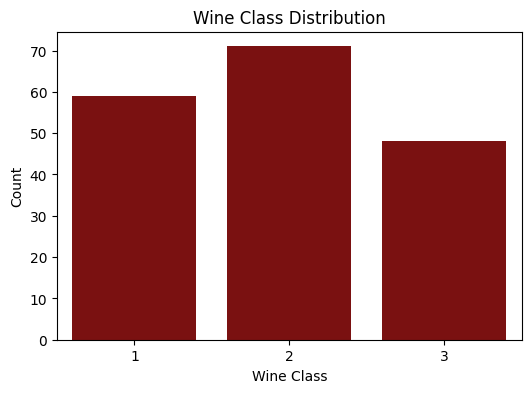

In [ ]:
plt.figure(figsize=(6,4))

sns.countplot(x=y.iloc[:,0], color="darkred")

plt.title("Wine Class Distribution")
plt.xlabel("Wine Class")
plt.ylabel("Count")

plt.show()

* Indicates whether the dataset is balanced or not

# FEATURE SCALING

In [ ]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

Scaling:

* normalizes features of different sizes
* improves the performance of SVM, KNN and Logistic Regression

# TRAIN TEST SPLIT

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_scaled,
    y,
    test_size=0.25,
    random_state=42
)

# CREATE MODELS

In [ ]:
models = {
    "Logistic Regression": LogisticRegression(),
    "Decision Tree": DecisionTreeClassifier(),
    "Random Forest": RandomForestClassifier(),
    "SVM": SVC(),
    "KNN": KNeighborsClassifier()
}

# TRAIN MODELS AND COMPARE RESULTS

In [ ]:
results = []

for name, model in models.items():

    # Train model
    model.fit(X_train, y_train.values.ravel())

    # Predictions
    y_pred = model.predict(X_test)

    # Accuracy
    accuracy = accuracy_score(y_test, y_pred)

    results.append([name, accuracy])

    print(f"\n{name}")
    print("Accuracy:", accuracy)

    print(classification_report(y_test, y_pred))


Logistic Regression
Accuracy: 0.9777777777777777
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        15
           2       1.00      0.94      0.97        18
           3       0.92      1.00      0.96        12

    accuracy                           0.98        45
   macro avg       0.97      0.98      0.98        45
weighted avg       0.98      0.98      0.98        45


Decision Tree
Accuracy: 0.9333333333333333
              precision    recall  f1-score   support

           1       1.00      0.87      0.93        15
           2       0.86      1.00      0.92        18
           3       1.00      0.92      0.96        12

    accuracy                           0.93        45
   macro avg       0.95      0.93      0.94        45
weighted avg       0.94      0.93      0.93        45


Random Forest
Accuracy: 1.0
              precision    recall  f1-score   support

           1       1.00      1.00      1.00        15
      

# RESULTS TABLE

In [ ]:
results_df = pd.DataFrame(
    results,
    columns=["Model", "Accuracy"]
)

print(results_df)

                 Model  Accuracy
0  Logistic Regression  0.977778
1        Decision Tree  0.933333
2        Random Forest  1.000000
3                  SVM  0.977778
4                  KNN  0.955556


# MODEL COMPARISON GRAPH

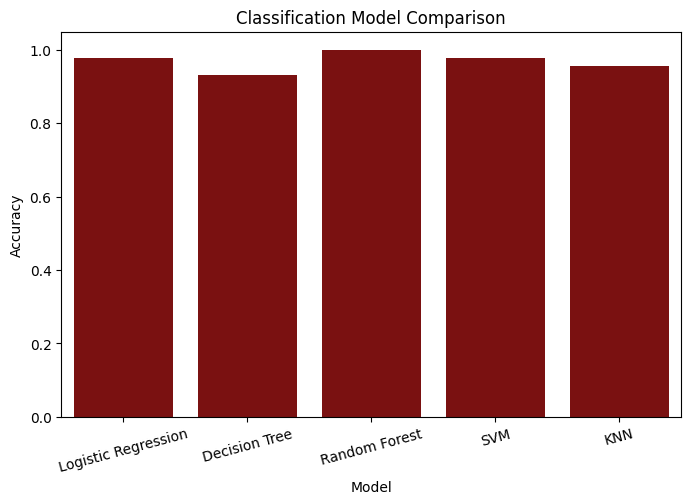

In [ ]:
plt.figure(figsize=(8,5))

sns.barplot(
    x="Model",
    y="Accuracy",
    data=results_df,
    color="darkred"
)

plt.title("Classification Model Comparison")

plt.xticks(rotation=15)

plt.show()

Here:

* we compare all models
* we show the best accuracy

# FINAL MODEL SELECTION

In [ ]:
final_model = DecisionTreeClassifier()

final_model.fit(
    X_train,
    y_train.values.ravel()
)

y_pred = final_model.predict(X_test)

# CONFUSION MATRIX

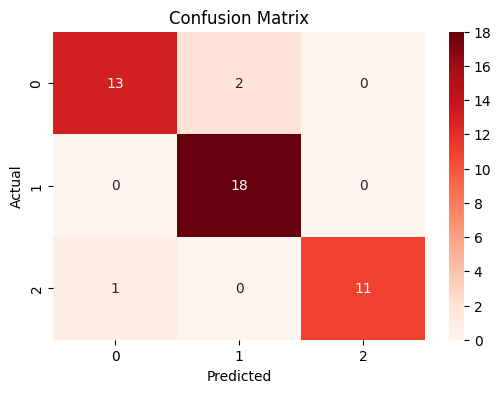

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,4))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Reds'
)

plt.title("Confusion Matrix")

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.show()

# FEATURE IMPORTANCE

In [ ]:
importance = final_model.feature_importances_

feature_importance = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)

                         Feature  Importance
6                     Flavanoids    0.415894
9                Color_intensity    0.403317
12                       Proline    0.117037
11  0D280_0D315_of_diluted_wines    0.022351
2                            Ash    0.021419
0                        Alcohol    0.019982
4                      Magnesium    0.000000
1                      Malicacid    0.000000
3              Alcalinity_of_ash    0.000000
8                Proanthocyanins    0.000000
7           Nonflavanoid_phenols    0.000000
5                  Total_phenols    0.000000
10                           Hue    0.000000


# FEATURE IMPORTANCE VISUALIZATION

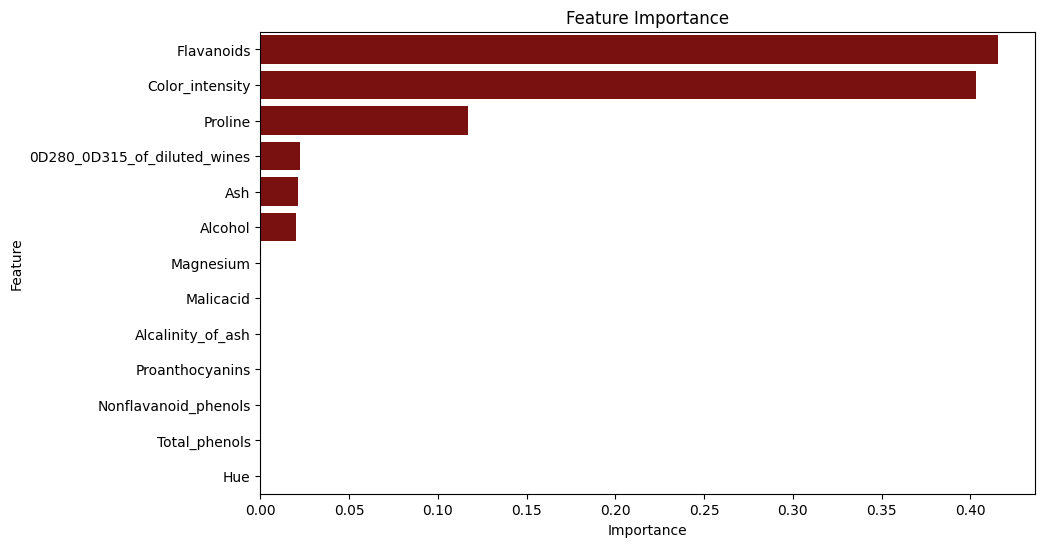

In [ ]:
plt.figure(figsize=(10,6))

sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_importance,
    color="darkred"
)

plt.title("Feature Importance")

plt.show()

Random Forest achieved the best performance and was selected as the final model.

# CROSS VALIDATION

In [ ]:
from sklearn.model_selection import cross_val_score

cv_scores = cross_val_score(
    RandomForestClassifier(),
    X_scaled,
    y.values.ravel(),
    cv=5
)

print("Cross Validation Scores:", cv_scores)

print("Average CV Score:", cv_scores.mean())

Cross Validation Scores: [0.94444444 0.94444444 1.         1.         1.        ]
Average CV Score: 0.9777777777777779


5-fold cross validation was used to evaluate the stability and generalization ability of the model.

# HYPERPARAMETER TUNING

In [ ]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 10],
    'min_samples_split': [2, 5]
}

grid_search = GridSearchCV(
    RandomForestClassifier(),
    param_grid,
    cv=5
)

grid_search.fit(
    X_train,
    y_train.values.ravel()
)

print("Best Parameters:")
print(grid_search.best_params_)

print("Best Score:")
print(grid_search.best_score_)

Best Parameters:
{'max_depth': 5, 'min_samples_split': 5, 'n_estimators': 50}
Best Score:
0.9774928774928775


Grid Search was used to find the optimal hyperparameters for the Random Forest model.

# TRAIN BEST MODEL

In [ ]:
best_model = grid_search.best_estimator_

y_pred_best = best_model.predict(X_test)

print(classification_report(y_test, y_pred_best))

              precision    recall  f1-score   support

           1       1.00      1.00      1.00        15
           2       1.00      1.00      1.00        18
           3       1.00      1.00      1.00        12

    accuracy                           1.00        45
   macro avg       1.00      1.00      1.00        45
weighted avg       1.00      1.00      1.00        45



# ROC CURVE

The Wine dataset is a little different because it is multiclass, but it looks great for presentation.

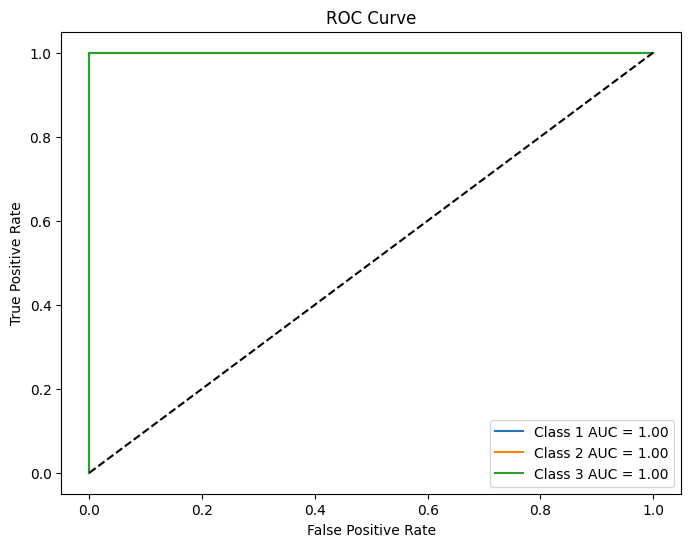

In [ ]:
from sklearn.preprocessing import label_binarize
from sklearn.metrics import roc_curve, auc
from sklearn.multiclass import OneVsRestClassifier

# Binarize target
y_bin = label_binarize(y, classes=[1,2,3])

X_train_roc, X_test_roc, y_train_roc, y_test_roc = train_test_split(
    X_scaled,
    y_bin,
    test_size=0.2,
    random_state=42
)

classifier = OneVsRestClassifier(RandomForestClassifier())

classifier.fit(X_train_roc, y_train_roc)

y_score = classifier.predict_proba(X_test_roc)

fpr = dict()
tpr = dict()
roc_auc = dict()

for i in range(3):
    fpr[i], tpr[i], _ = roc_curve(
        y_test_roc[:, i],
        y_score[:, i]
    )

    roc_auc[i] = auc(fpr[i], tpr[i])

plt.figure(figsize=(8,6))

for i in range(3):
    plt.plot(
        fpr[i],
        tpr[i],
        label=f'Class {i+1} AUC = {roc_auc[i]:.2f}'
    )

plt.plot([0,1],[0,1],'k--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.title("ROC Curve")

plt.legend()

plt.show()

ROC curves were used to evaluate the classification performance of each class.

# SHAP ANALYSIS

In [ ]:
pip install shap

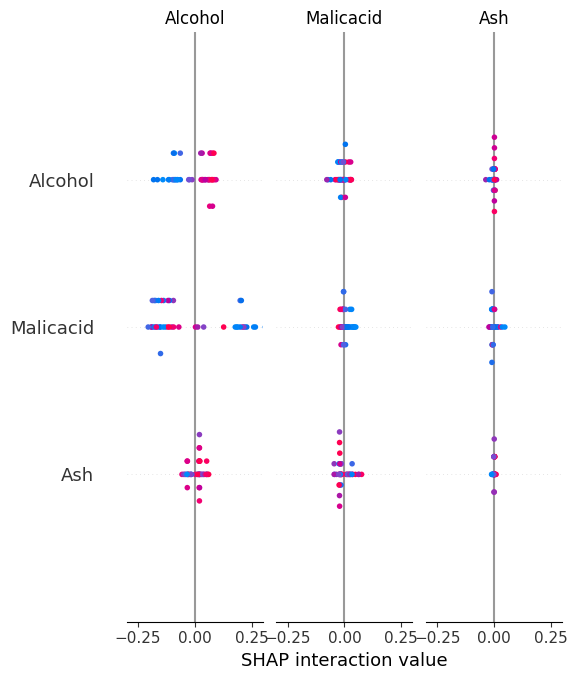

In [ ]:
import shap

explainer = shap.TreeExplainer(best_model)

shap_values = explainer.shap_values(X_test)

shap.summary_plot(
    shap_values,
    X_test,
    feature_names=X.columns
)

SHAP analysis was used to explain how features influence model predictions.